# Temperature change: patterns and physical mechanisms


1. Global-mean temperature, anomalies, and reference periods
2. Land–ocean warming differences and the surface energy budget
3. Greenhouse forcing, planetary energy imbalance, and ocean heat uptake
4. Equilibrium climate sensitivity (ECS), logarithmic CO₂ dependence, and transient versus equilibrium warming
5. A simple energy-balance calculation



## 0. Setup 

We use NumPy, pandas, and Matplotlib. The lecture's main message is that global warming is not spatially or vertically uniform, and that the long-term trend coexists with variability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11
})

## 1. Global-mean temperature and anomalies (10 min)

The slides define global-mean surface temperature (GMST) as a combination of near-surface air temperature over land and sea-surface temperature over ocean. Different datasets may differ because of coverage and methods, but the long-term warming trend is robust.

An anomaly is the departure from a reference-period average:

\[
T'(t)=T(t)-\overline{T}_{\mathrm{ref}}.
\]

The reference period determines the zero point. Changing the reference period shifts the anomaly values, but does not change the underlying differences through time.

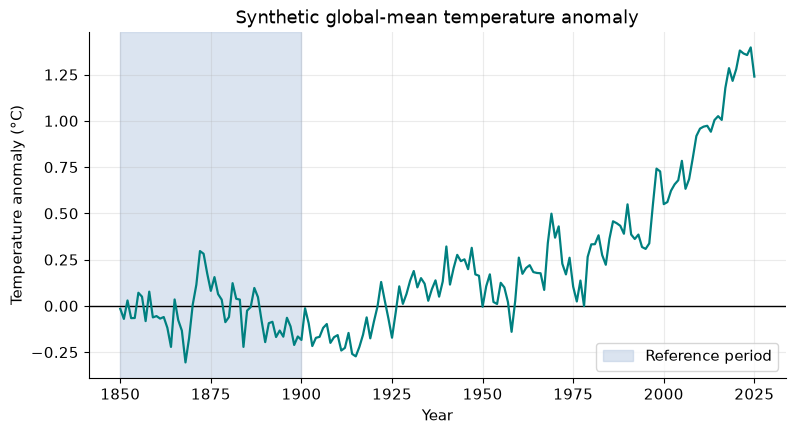

In [5]:
# Synthetic annual series: long-term change + year-to-year variability
years = np.arange(1850, 2026)
trend = np.interp(years, [1850, 1910, 1945, 1975, 2000, 2025],
                  [-0.15, -0.25, 0.05, 0.02, 0.50, 1.20])
noise = np.zeros(len(years))
for i in range(1, len(years)):
    noise[i] = 0.55 * noise[i-1] + rng.normal(0, 0.09)
synthetic_gmst = trend + noise

baseline = (years >= 1900) & (years <= 1950)
anom_1850_1900 = synthetic_gmst - synthetic_gmst[baseline].mean()

plt.axvspan(1850, 1900, color="lightsteelblue", alpha=0.45, label="Reference period")
plt.axhline(0, color="black", lw=1)
plt.plot(years, anom_1850_1900, color="teal", lw=1.6)
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.title("Synthetic global-mean temperature anomaly")
plt.legend()
plt.show()

### Activity 1A — calculate the anomaly averages

Calculate the mean anomaly over the reference period and over 1991–2020. The first should be approximately zero by definition.

Then calculate the same series relative to 1991–2020 and plot both versions.

Mean anomaly, 1850–1900: 2.3401759832785162e-17
Mean anomaly, 1991–2020: 0.761136245167355


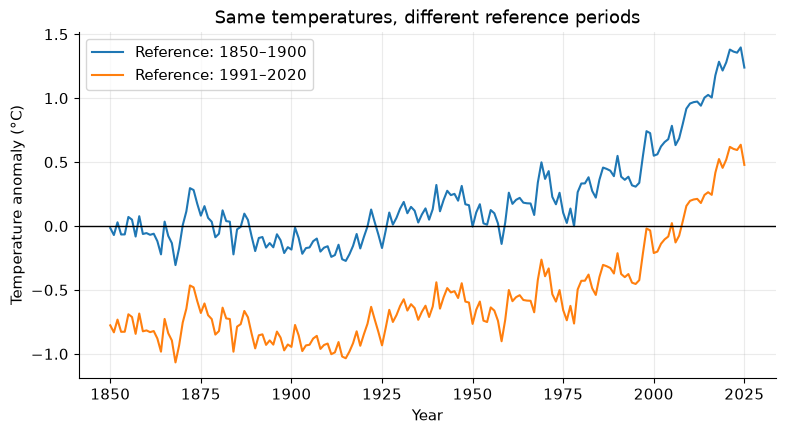

In [7]:
baseline = (years >= 1900) & (years <= 1950)
recent = (years >= 1991) & (years <= 2020)
print("Mean anomaly, 1850–1900:", anom_1850_1900[baseline].mean())
print("Mean anomaly, 1991–2020:", anom_1850_1900[recent].mean())

anom_1991_2020 = synthetic_gmst - synthetic_gmst[recent].mean()

plt.plot(years, anom_1850_1900, label="Reference: 1850–1900")
plt.plot(years, anom_1991_2020, label="Reference: 1991–2020")
plt.axhline(0, color="black", lw=1)
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.title("Same temperatures, different reference periods")
plt.legend()
plt.show()

**Discuss:** Why do the anomaly values change when the reference period changes, even though the warming history is the same?

### Activity 1B — quantify recent warming in the  series

Calculate the mean anomaly for 2011–2025 relative to 1850–1900. This is an exercise in calculating a difference from a reference period; it is not intended to match an observed estimate.

In [8]:
last_period = (years >= 2011) & (years <= 2025)
print("Mean anomaly, 2011–2025:",
      anom_1850_1900[last_period].mean(), "°C")

Mean anomaly, 2011–2025: 1.1742334919265518 °C


## 2. Land warms faster than ocean 

The slides identify several processes behind the land–ocean contrast:

- ocean heat storage and vertical mixing;
- ocean circulation redistributing heat horizontally and vertically;
- surface energy partitioning;
- moisture availability and evaporation;
- snow, ice, and other feedbacks.

The surface energy budget partitions available energy into latent heat, sensible heat, ground heat storage, and other terms. When land is water-limited, reduced evapotranspiration can shift energy from latent to sensible heat, reinforcing surface warming.

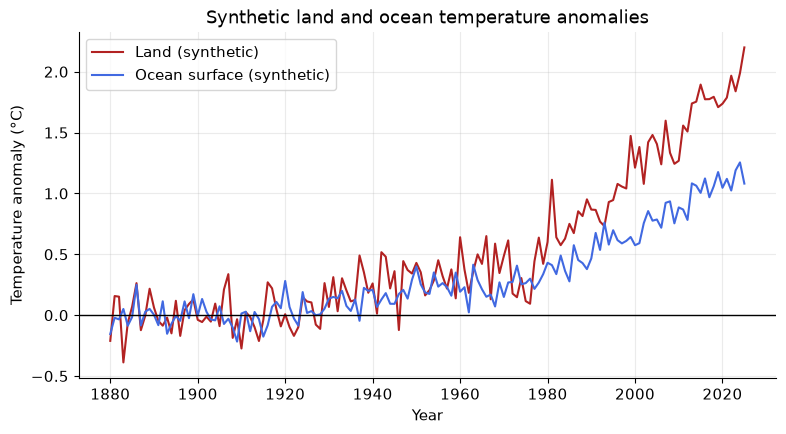

In [17]:
years_lo = np.arange(1880, 2026)
common_signal = np.interp(years_lo, [1880, 1910, 1945, 1975, 2000, 2025],
                           [-0.10, -0.20, 0.05, 0.10, 0.60, 1.15])
land_anom = 1.59 * common_signal + rng.normal(0, 0.15, len(years_lo))
ocean_anom = 0.88 * common_signal + rng.normal(0, 0.09, len(years_lo))
ref_lo = (years_lo >= 1880) & (years_lo <= 1900)
land_anom -= land_anom[ref_lo].mean()
ocean_anom -= ocean_anom[ref_lo].mean()

plt.plot(years_lo, land_anom, color="firebrick", label="Land (synthetic)")
plt.plot(years_lo, ocean_anom, color="royalblue", label="Ocean surface (synthetic)")
plt.axhline(0, color="black", lw=1)
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.title("Synthetic land and ocean temperature anomalies")
plt.legend()
plt.show()

### Activity 2A — compare the two series

1. Calculate mean anomalies over 2001–2025.
2. Calculate linear trends over 1980–2025 in °C per decade.
3. Explain why the ocean response is slower in terms of the processes listed in the slides.

In [6]:
recent_lo = (years_lo >= 2001) & (years_lo <= 2025)
trend_lo = (years_lo >= 1980) & (years_lo <= 2025)
print("Land mean, 2001–2025:", land_anom[recent_lo].mean(), "°C")
print("Ocean mean, 2001–2025:", ocean_anom[recent_lo].mean(), "°C")
land_trend = np.polyfit(years_lo[trend_lo], land_anom[trend_lo], 1)[0] * 10
ocean_trend = np.polyfit(years_lo[trend_lo], ocean_anom[trend_lo], 1)[0] * 10
print(f"Land trend, 1980–2025: {land_trend:.3f} °C/decade")
print(f"Ocean trend, 1980–2025: {ocean_trend:.3f} °C/decade")

Land mean, 2001–2025: 1.4100380354101165 °C
Ocean mean, 2001–2025: 0.7754629948773332 °C
Land trend, 1980–2025: 0.273 °C/decade
Ocean trend, 1980–2025: 0.162 °C/decade


### Activity 2B — surface energy partitioning

Use the artificial energy budget below. The units are arbitrary energy-flux units, chosen only to demonstrate that the terms partition the available energy. Increase the latent-heat fraction to represent a wetter surface, then reduce it to represent a water-limited surface. What happens to the sensible-heat fraction if total available energy is held fixed?

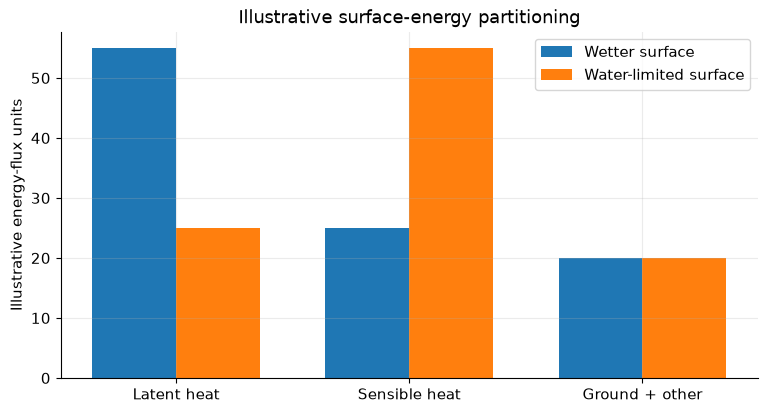

In [10]:
available_energy = 100
latent_wet = 55
sensible_wet = 25
ground_and_other_wet = available_energy - latent_wet - sensible_wet

latent_dry = 25
sensible_dry = 55
ground_and_other_dry = available_energy - latent_dry - sensible_dry

labels = ["Latent heat", "Sensible heat", "Ground + other"]
wet = [latent_wet, sensible_wet, ground_and_other_wet]
dry = [latent_dry, sensible_dry, ground_and_other_dry]
x = np.arange(len(labels))
w = 0.36
plt.bar(x-w/2, wet, w, label="Wetter surface")
plt.bar(x+w/2, dry, w, label="Water-limited surface")
plt.xticks(x, labels)
plt.ylabel("Illustrative energy-flux units")
plt.title("Illustrative surface-energy partitioning")
plt.legend()
plt.show()

**Interpret:** This toy budget represents the slide's mechanism qualitatively. It is not a measured surface energy budget, and the numbers are not intended as typical real-world values.

## 3. Greenhouse forcing and ocean heat uptake 

The slides describe the sequence:

1. Greenhouse forcing initially reduces the energy escaping to space.
2. The Earth system gains heat because incoming energy exceeds outgoing energy.
3. The ocean absorbs most of the accumulated heat; mixing and circulation transfer heat below the surface.
4. As the surface warms, outgoing infrared radiation increases and the energy imbalance gradually declines.

Use a simplified energy-balance expression:

\[
N=F-\lambda_{LW}\Delta T
\]

where \(N\) is the remaining energy imbalance, \(F\) is effective radiative forcing, and \(\lambda_{LW}\Delta T\) is the increase in outgoing longwave radiation. Units are W m⁻² for the flux terms.

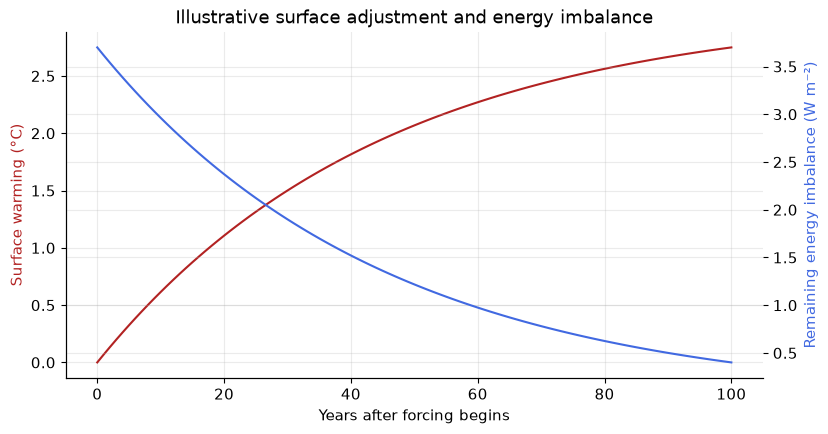

In [11]:
time = np.arange(0, 101)   # years after a step forcing
F = 3.7                   # illustrative forcing, W m-2
lambda_lw = 1.2           # illustrative radiative response, W m-2 K-1
# Gradual surface adjustment, selected for teaching rather than calibrated to observations
delta_T = (F / lambda_lw) * (1 - np.exp(-time / 45))
N = F - lambda_lw * delta_T

fig, ax = plt.subplots()
ax.plot(time, delta_T, color="firebrick")
ax.set_xlabel("Years after forcing begins")
ax.set_ylabel("Surface warming (°C)", color="firebrick")
ax2 = ax.twinx()
ax2.plot(time, N, color="royalblue")
ax2.set_ylabel("Remaining energy imbalance (W m⁻²)", color="royalblue")
ax.set_title("Illustrative surface adjustment and energy imbalance")
plt.show()

### Activity 3 — interpret the energy budget

1. Why does the surface temperature rise?
2. Why does the energy imbalance decline over time in this model?
3. What does the energy imbalance approach at long times?
4. Explain how ocean heat uptake delays surface warming without removing the accumulated heat from the climate system.

## 4. Equilibrium climate sensitivity and logarithmic CO₂ dependence

The lecture defines **equilibrium climate sensitivity (ECS)** as the long-term global surface warming after atmospheric CO₂ doubles and the climate approaches a new equilibrium, with fast feedbacks included.

For a simplified relationship, each doubling adds the same equilibrium warming:

\[
\Delta T = ECS\,\log_2\left(\frac{C}{C_0}\right)
\]

Using \(C_0=280\) ppm and \(ECS=3^\circ\mathrm{C}\), doubling from 280 to 560 ppm gives 3°C; doubling again to 1120 ppm gives 6°C relative to 280 ppm.

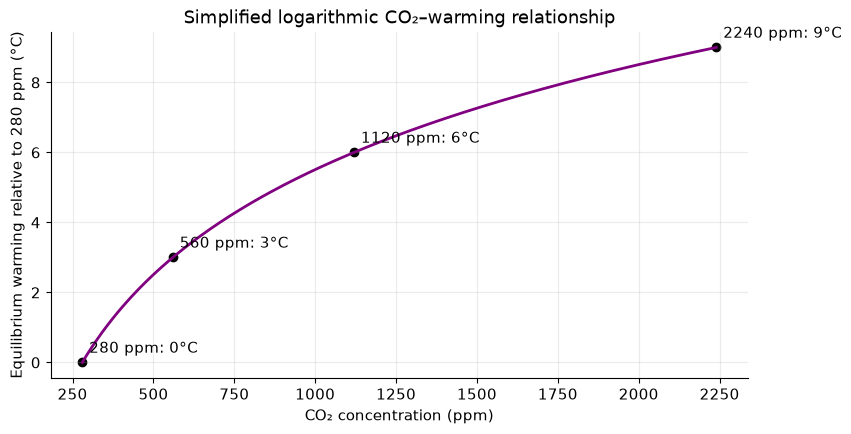

In [12]:
C0 = 280
ECS = 3.0
co2 = np.linspace(280, 2240, 250)
eq_warming = ECS * np.log2(co2 / C0)

plt.plot(co2, eq_warming, color="purple", lw=2)
for c in [280, 560, 1120, 2240]:
    val = ECS * np.log2(c / C0)
    plt.scatter(c, val, color="black")
    plt.annotate(f"{c} ppm: {val:.0f}°C", (c, val),
                 xytext=(5, 7), textcoords="offset points")
plt.xlabel("CO₂ concentration (ppm)")
plt.ylabel("Equilibrium warming relative to 280 ppm (°C)")
plt.title("Simplified logarithmic CO₂–warming relationship")
plt.show()

### Activity 4A — reproduce the lecture calculation

The slides use 500 ppm as an example concentration.

1. Calculate \(500/280\).
2. Calculate the number of doublings, \(n=\log_2(C/C_0)\).
3. Multiply by ECS = 3°C to estimate the equilibrium warming.
4. Compare this equilibrium estimate with the observed warming of about 1.1–1.2°C quoted in the slides. Why are they not the same?

In [20]:
C = 500
ratio = C / C0
n_doublings = np.log2(ratio)
warming_equilibrium = ECS * n_doublings
print(f"Concentration ratio: {ratio:.3f}")
print(f"Number of doublings: {n_doublings:.3f}")
print(f"Illustrative equilibrium warming: {warming_equilibrium:.2f} °C")
print("The lecture notes that this is larger than observed warming so far.")

Concentration ratio: 1.786
Number of doublings: 0.837
Illustrative equilibrium warming: 2.51 °C
The lecture notes that this is larger than observed warming so far.


### Activity 4B — vary ECS

Compare the equilibrium warming for ECS values of 2, 3, and 4°C per doubling. This is a sensitivity experiment: it shows how the assumed ECS affects the equilibrium estimate.

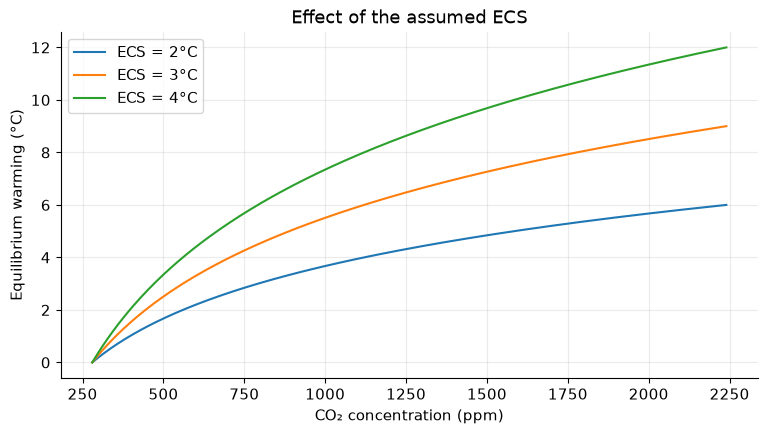

In [21]:
for ecs_test in [2, 3, 4]:
    plt.plot(co2, ecs_test * np.log2(co2/C0), label=f"ECS = {ecs_test}°C")
plt.xlabel("CO₂ concentration (ppm)")
plt.ylabel("Equilibrium warming (°C)")
plt.title("Effect of the assumed ECS")
plt.legend()
plt.show()

## 5. Present-day energy imbalance versus equilibrium 
The slides distinguish current warming from equilibrium warming. Today, forcing is split between increased outgoing radiation as the surface warms and energy still being stored, especially in the ocean. At equilibrium, net additional heat uptake is zero.

The current radiative forcing anomaly due to anthropogenic emissions is 2.3 W/m², the current global-mean surface warming is 1°C. Assume 50\% of the radiative forcing heat flux anomaly currently goes into the ocean. Estimate the equilibrium warming at a double-preindustrial CO₂ concentration ($2\times280$ ppm), assuming that this corresponds to a radiative forcing of 4 W/m².

In [16]:
Delta_F=2.3
Delta_Q=0.5*Delta_F
Delta_F2x=4
Delta_T=1
Delta_T2x=Delta_F2x*Delta_T/(Delta_F-Delta_Q)
print("The expected equilibrium (steady-state) warming is ",Delta_T2x)

The expected equilibrium (steady-state) warming is  3.4782608695652177


### Final questions

1. In the present-day equation, what does the residual ΔQnow represent physically?
2. What becomes zero at equilibrium?
3. Why is ECS not the same as warming observed over a few decades?
4. In one sentence, connect greenhouse forcing, ocean heat uptake, and the time required to approach equilibrium.